Personal loans are a lucrative revenue stream for banks. The typical interest rate of a two-year loan in the United Kingdom is [around 10%](https://www.experian.com/blogs/ask-experian/whats-a-good-interest-rate-for-a-personal-loan/). This might not sound like a lot, but in September 2022 alone UK consumers borrowed [around £1.5 billion](https://www.ukfinance.org.uk/system/files/2022-12/Household%20Finance%20Review%202022%20Q3-%20Final.pdf), which would mean approximately £300 million in interest generated by banks over two years!

You have been asked to work with a bank to clean the data they collected as part of a recent marketing campaign, which aimed to get customers to take out a personal loan. They plan to conduct more marketing campaigns going forward so would like you to ensure it conforms to the specific structure and data types that they specify so that they can then use the cleaned data you provide to set up a PostgreSQL database, which will store this campaign's data and allow data from future campaigns to be easily imported. 

They have supplied you with a csv file called `"bank_marketing.csv"`, which you will need to clean, reformat, and split the data, saving three final csv files. Specifically, the three files should have the names and contents as outlined below:

## `client.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `age` | `integer` | Client's age in years | N/A |
| `job` | `object` | Client's type of job | Change `"."` to `"_"` |
| `marital` | `object` | Client's marital status | N/A |
| `education` | `object` | Client's level of education | Change `"."` to `"_"` and `"unknown"` to `np.NaN` |
| `credit_default` | `bool` | Whether the client's credit is in default | Convert to `boolean` data type:<br> `1` if `"yes"`, otherwise `0` |
| `mortgage` | `bool` | Whether the client has an existing mortgage (housing loan) | Convert to boolean data type:<br> `1` if `"yes"`, otherwise `0` |

<br>

## `campaign.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `number_contacts` | `integer` | Number of contact attempts to the client in the current campaign | N/A |
| `contact_duration` | `integer` | Last contact duration in seconds | N/A |
| `previous_campaign_contacts` | `integer` | Number of contact attempts to the client in the previous campaign | N/A |
| `previous_outcome` | `bool` | Outcome of the previous campaign | Convert to boolean data type:<br> `1` if `"success"`, otherwise `0`. |
| `campaign_outcome` | `bool` | Outcome of the current campaign | Convert to boolean data type:<br> `1` if `"yes"`, otherwise `0`. |
| `last_contact_date` | `datetime` | Last date the client was contacted | Create from a combination of `day`, `month`, and a newly created `year` column (which should have a value of `2022`); <br> **Format =** `"YYYY-MM-DD"` |

<br>

## `economics.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `cons_price_idx` | `float` | Consumer price index (monthly indicator) | N/A |
| `euribor_three_months` | `float` | Euro Interbank Offered Rate (euribor) three-month rate (daily indicator) | N/A |

Personal loans are a lucrative revenue stream for banks. The typical interest rate of a two-year loan in the United Kingdom is [around 10%](https://www.experian.com/blogs/ask-experian/whats-a-good-interest-rate-for-a-personal-loan/). This might not sound like a lot, but in September 2022 alone UK consumers borrowed [around £1.5 billion](https://www.ukfinance.org.uk/system/files/2022-12/Household%20Finance%20Review%202022%20Q3-%20Final.pdf), which would mean approximately £300 million in interest generated by banks over two years!

You have been asked to work with a bank to clean the data they collected as part of a recent marketing campaign, which aimed to get customers to take out a personal loan. They plan to conduct more marketing campaigns going forward so would like you to ensure it conforms to the specific structure and data types that they specify so that they can then use the cleaned data you provide to set up a PostgreSQL database, which will store this campaign's data and allow data from future campaigns to be easily imported.

They have supplied you with a csv file called `"bank_marketing.csv"`, which you will need to clean, reformat, and split the data, saving three final csv files. Specifically, the three files should have the names and contents as outlined below:

## `client.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `age` | `integer` | Client's age in years | N/A |
| `job` | `object` | Client's type of job | Change `"."` to `"_"` |
| `marital` | `object` | Client's marital status | N/A |
| `education` | `object` | Client's level of education | Change `"."` to `"_"` and `"unknown"` to `np.NaN` |
| `credit_default` | `bool` | Whether the client's credit is in default | Convert to `boolean` data type:<br> `1` if `"yes"`, otherwise `0` |
| `mortgage` | `bool` | Whether the client has an existing mortgage (housing loan) | Convert to boolean data type:<br> `1` if `"yes"`, otherwise `0` |

<br>

## `campaign.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `number_contacts` | `integer` | Number of contact attempts to the client in the current campaign | N/A |
| `contact_duration` | `integer` | Last contact duration in seconds | N/A |
| `previous_campaign_contacts` | `integer` | Number of contact attempts to the client in the previous campaign | N/A |
| `previous_outcome` | `bool` | Outcome of the previous campaign | Convert to boolean data type:<br> `1` if `"success"`, otherwise `0`. |
| `campaign_outcome` | `bool` | Outcome of the current campaign | Convert to boolean data type:<br> `1` if `"yes"`, otherwise `0`. |
| `last_contact_date` | `datetime` | Last date the client was contacted | Create from a combination of `day`, `month`, and a newly created `year` column (which should have a value of `2022`); <br> **Format =** `"YYYY-MM-DD"` |

<br>

## `economics.csv`

| column | data type | description | cleaning requirements |
|--------|-----------|-------------|-----------------------|
| `client_id` | `integer` | Client ID | N/A |
| `cons_price_idx` | `float` | Consumer price index (monthly indicator) | N/A |
| `euribor_three_months` | `float` | Euro Interbank Offered Rate (euribor) three-month rate (daily indicator) | N/A |

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("bank_marketing.csv")

for col in ["credit_default", "mortgage", "previous_outcome", "campaign_outcome"]:
    print(col)
    print("--------------")
    print(df[col].value_counts())

credit_default
--------------
credit_default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64
mortgage
--------------
mortgage
yes        21576
no         18622
unknown      990
Name: count, dtype: int64
previous_outcome
--------------
previous_outcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64
campaign_outcome
--------------
campaign_outcome
no     36548
yes     4640
Name: count, dtype: int64


In [3]:
df.head()

,client_id,age,job,marital,education,credit_default,mortgage,month,day,contact_duration,number_contacts,previous_campaign_contacts,previous_outcome,cons_price_idx,euribor_three_months,campaign_outcome
0,0,56,housemaid,married,basic.4y,no,no,may,13,261,1,0,nonexistent,93.994,4.857,no
1,1,57,services,married,high.school,unknown,no,may,19,149,1,0,nonexistent,93.994,4.857,no
2,2,37,services,married,high.school,no,yes,may,23,226,1,0,nonexistent,93.994,4.857,no
3,3,40,admin.,married,basic.6y,no,no,may,27,151,1,0,nonexistent,93.994,4.857,no
4,4,56,services,married,high.school,no,no,may,3,307,1,0,nonexistent,93.994,4.857,no


In [4]:
client_df = df[["client_id", "age", "job", "marital", "education", "credit_default", "mortgage"]]


month_map = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
             'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}

df['month_num'] = df['month'].str.lower().map(month_map)
df['last_contact_date'] = pd.to_datetime({'year': 2022,  # Placeholder year
                                          'month': df['month_num'],
                                          'day': df['day']})

campaign_df = df[["client_id", "number_contacts", "contact_duration", "previous_campaign_contacts", "previous_outcome", "campaign_outcome", "last_contact_date"]]
# Additionally, it should contain "last_contact_date", a column you can create using the "month" and "day"

economics_df = df[["cons_price_idx", "euribor_three_months"]]

campaign_df.head()

,client_id,number_contacts,contact_duration,previous_campaign_contacts,previous_outcome,campaign_outcome,last_contact_date
0,0,1,261,0,nonexistent,no,2022-05-13
1,1,1,149,0,nonexistent,no,2022-05-19
2,2,1,226,0,nonexistent,no,2022-05-23
3,3,1,151,0,nonexistent,no,2022-05-27
4,4,1,307,0,nonexistent,no,2022-05-03


## Data Cleaning and Feature Engineering

In this section, we will:
- Clean the `education` and `job` columns by replacing periods and handling unknowns.
- Convert `campaign_outcome` and `previous_outcome` to binary/boolean values.
- Create new columns (`year`, string version of `day`, and a formatted date column).
- Remove unnecessary columns after feature engineering.

In [10]:
import numpy as np
import pandas as pd

# Reload fresh data to avoid re-run issues
df = pd.read_csv("bank_marketing.csv")  # adjust filename/path as needed

# --- Cleaning columns ---
df["education"] = df["education"].str.replace(".", "_", regex=False)
df["education"] = df["education"].replace("unknown", np.nan)

df["job"] = df["job"].str.replace(".", "", regex=False)

df["campaign_outcome"] = df["campaign_outcome"].map({"yes": 1, "no": 0}).astype(bool)
df["previous_outcome"] = df["previous_outcome"].map({"success": 1, "failure": 0, "nonexistent": 0}).astype(bool)

# --- Creating new columns ---
df["year"] = "2022"
df["day"] = df["day"].astype(str)
df["last_contact_date"] = df["year"] + "-" + df["month"] + "-" + df["day"]
df["last_contact_date"] = pd.to_datetime(df["last_contact_date"], format="%Y-%b-%d")

# --- Drop unneeded columns ---
df.drop(columns=["month", "day", "year"], inplace=True)

# --- Build the three DataFrames ---
client_df = df[["client_id", "age", "job", "marital", "education", "credit_default", "mortgage"]]

campaign_df = df[["client_id", "number_contacts", "contact_duration",
                   "previous_campaign_contacts", "previous_outcome",
                   "campaign_outcome", "last_contact_date"]]

economics_df = df[["cons_price_idx", "euribor_three_months"]]

In [11]:
client_df.head()

,client_id,age,job,marital,education,credit_default,mortgage
0,0,56,housemaid,married,basic_4y,no,no
1,1,57,services,married,high_school,unknown,no
2,2,37,services,married,high_school,no,yes
3,3,40,admin,married,basic_6y,no,no
4,4,56,services,married,high_school,no,no


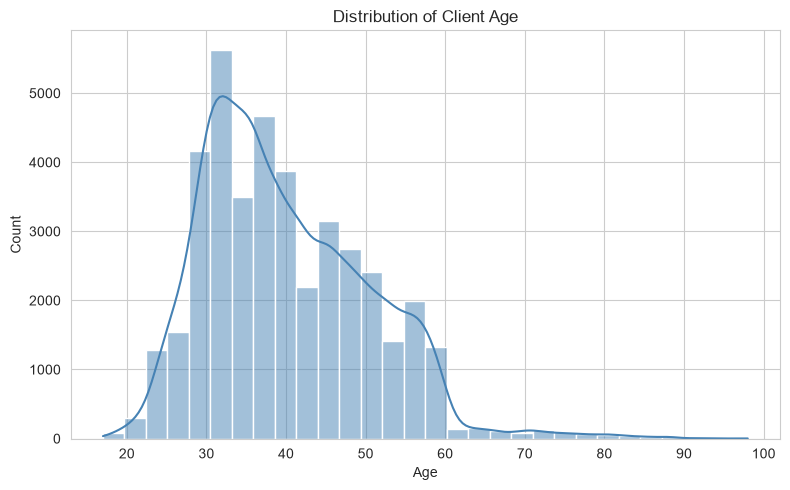

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=client_df, x="age", bins=30, kde=True, color="steelblue")

plt.title("Distribution of Client Age")
plt.xlabel("Age")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

## Conclusion

Client age is right-skewed, with the bulk of clients concentrated between **30 and 50 years old** and a peak around the early 30s. The distribution tails off gradually beyond 60, with relatively few clients above 70. This skew suggests age could be worth binning into groups (e.g. young adult, mid-career, senior) for downstream analysis or modelling, rather than treating it as a purely linear feature.

In [12]:
campaign_df.head()

,client_id,number_contacts,contact_duration,previous_campaign_contacts,previous_outcome,campaign_outcome,last_contact_date
0,0,1,261,0,False,False,2022-05-13
1,1,1,149,0,False,False,2022-05-19
2,2,1,226,0,False,False,2022-05-23
3,3,1,151,0,False,False,2022-05-27
4,4,1,307,0,False,False,2022-05-03


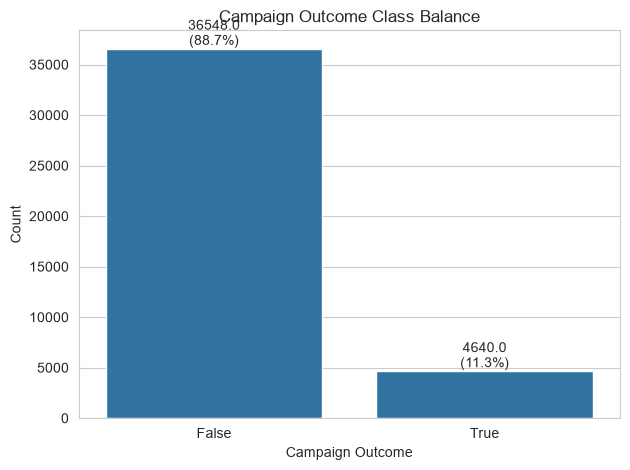

In [19]:
ax = sns.countplot(data=campaign_df, x="campaign_outcome")

plt.title("Campaign Outcome Class Balance")
plt.xlabel("Campaign Outcome")
plt.ylabel("Count")

# annotate bars with counts and percentages
total = len(campaign_df)
for p in ax.patches:
    count = p.get_height()
    pct = 100 * count / total
    ax.annotate(f"{count}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2, count),
                ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Conclusion

The campaign outcome variable is heavily imbalanced: **88.7%** of clients did not subscribe to a personal loan (`False`), while only **11.3%** did (`True`). This class imbalance is an important consideration for any future modelling work on this data — accuracy alone would be a misleading metric, since a model that always predicts `False` would already be ~89% "accurate" without learning anything useful. Techniques such as class weighting, resampling (e.g. SMOTE), or metrics like precision, recall, and F1-score would be more appropriate for evaluating performance on this dataset.

In [13]:
economics_df.head()

,cons_price_idx,euribor_three_months
0,93.994,4.857
1,93.994,4.857
2,93.994,4.857
3,93.994,4.857
4,93.994,4.857


In [6]:
client_df = client_df.copy()
client_df["credit_default"] = client_df["credit_default"].map({"yes": 1, "no": 0, "unknown": 0}).astype(bool)
client_df["mortgage"] = client_df["mortgage"].map({"yes": 1, "no": 0, "unknown": 0}).astype(bool)
economics_df = df[["client_id", "cons_price_idx", "euribor_three_months"]]

In [7]:
client_df.to_csv("client.csv", index=False)
campaign_df.to_csv("campaign.csv", index=False)
economics_df.to_csv("economics.csv", index=False)